# 05 · Hadrons: spectra, dN/dη, oversamples and weights

[![Open In Colab](https://colab.research.google.com/assets/colab-badge.svg)](https://colab.research.google.com/github/jhputschke/js-contrib/blob/main/tutorials/pyjetscape/05_hadrons.ipynb)

**Time:** 45 minutes · **Needs:** any setup · **Data:** `auau_stats`: the hadron files (0.2 GB, downloaded once)

A campaign of jet events is many files, many events, and for each event many samples of its
hadrons. Reading them is easy. Combining them correctly takes some care: which average is the
right one, how a background shared by several events counts, and how events from different
p̂T windows are put together. This tutorial reads a small campaign of 120 central Au+Au events
and:
- explains what a unit, a sample and an oversample are, and why each event is the mean over
  its oversamples;
- measures the charged-hadron $dN/d\eta$ and the identified spectra of π, K and p, for the
  background and for the jet events;
- combines three p̂T windows with their cross sections, and shows what goes wrong without them;
- looks at how well a window's cross section is known;
- checks the campaign for bad runs.

Reference pages: [Hadrons](https://jhputschke.github.io/js-contrib/analysis/hadrons/),
[What a production writes](https://jhputschke.github.io/js-contrib/analysis/files/#4-hadron-files).

> **Work in progress: examples, not vetted physics.** The tutorials show how to run the
> simulation and use its outputs. The data sets are small, so the statistics are low, and
> the analyses have not been checked to the standard of a publication: treat every number
> and figure as an illustration, not as a physics result.

> **The outputs shown** were produced on an Apple Silicon Mac, in the environment the xscape wheel 0.2.0 is built in, with the hydro on the GPU through Metal.

In [1]:
# Setup: the tutorial helpers sit next to this notebook (_common/). In Colab they are
# fetched first, with the jetscape readers; locally nothing is installed.
import os, sys, subprocess
if "google.colab" in sys.modules and not os.path.isdir("_common"):
    subprocess.run("curl -sL https://codeload.github.com/jhputschke/js-contrib/tar.gz/refs/heads/main"
                   " | tar xz --strip-components=3 js-contrib-main/tutorials/pyjetscape",
                   shell=True, check=True)
sys.path.insert(0, os.getcwd())
from _common import tutorial_env as te
te.colab_install()
env = te.setup()

tutorials v1.dev | setup: source (runs X-SCAPE; hydro: Metal GPU) | Python 3.13.1 | data: data/


## 1. The campaign

The set `auau_stats` holds four production jobs of 30 events each. Every job made 5 central
(0–10 %) Au+Au backgrounds at $\sqrt{s_{NN}} = 200$ GeV and, on each background, 6 jets: 2 in
each of the p̂T windows 10–20, 20–30 and 30–50 GeV. p̂T is the transverse momentum of the hard
scattering in its centre-of-mass frame. The leading hard parton was required to have rapidity
$|y| < 0.6$.

These are **hadrons-only** jobs (`run_prod_jet.py --hadrons-only`): the hadrons were sampled
inside the job, and no pair or particlize file was kept. The event record (background,
p̂T window, deposited energy, ...) is then stored in the hadron files themselves (`units/`), and
`HadronFileReader` reads it from there. It needs the files on disk, so we download them once:

In [2]:
import numpy as np
from jetscape.hadrons_h5 import HadronFileReader

SET = "auau_stats"
folder = te.fetch(SET, include=["*_hadrons_*.h5"], quiet=True)
r = HadronFileReader(str(folder))
print(f"{r.n_files} jobs, {r.n_events} events, tags {r.tags()}, correlated sampling: {r.correlated}")
print("pTHat windows [GeV]:", r.pthat_bins.tolist())
print("files of the first job:", sorted(p.name for p in folder.glob(os.path.basename(r.stems[0]) + "_hadrons_*.h5")))

4 jobs, 120 events, tags ('bulk_jet', 'bulk_bg', 'jet_frag'), correlated sampling: False
pTHat windows [GeV]: [[10.0, 20.0], [20.0, 30.0], [30.0, 50.0]]
files of the first job: ['AuAu_0_10_jet_stats_seed0201_hadrons_bulk_bg.h5', 'AuAu_0_10_jet_stats_seed0201_hadrons_bulk_jet.h5', 'AuAu_0_10_jet_stats_seed0201_hadrons_jet_frag.h5']


Each job wrote three hadron files, one per **tag**:

| tag | made from | one unit is | samples per unit here |
|---|---|---|---|
| `bulk_jet` | the freeze-out surface of the fluid **with** the jet's deposited energy | an event | 10 oversamples |
| `bulk_bg` | the freeze-out surface of the background fluid, **without** the jet | a background | 20 oversamples |
| `jet_frag` | the jet's final partons, hadronized by PYTHIA's string fragmentation | an event | 10 fragmentations |

A jet event is `bulk_jet` + `jet_frag`. The same collision without the jet is `bulk_bg`.

## 2. Units, samples and oversamples

**Units.** Every hadron has a PDG id `pid`, a status, and a four-momentum `p` =
$(E, p_x, p_y, p_z)$ in GeV. These files have no positions (`--no-x`): `x` is empty. The reader
adds the derived columns `pt`, `eta` (pseudorapidity), `y` (rapidity), `phi` and `charged`.

**Oversamples.** The fluid ends on a freeze-out surface, where it turns into hadrons. The
Cooper–Frye formula gives the *mean* number of each hadron species emitted from each piece
of the surface. One random draw of hadrons from it is one **oversample**. Drawing many
oversamples from the same surface beats down the noise of the sampling. But they all come
from the same fluid, the same initial state and the same jet: **ten oversamples are not ten
collisions**. Likewise, the ten fragmentations of `jet_frag` are ten hadronizations of the same
final partons.

Look at event 0 (and the background it sits on):

In [3]:
info = r.event_info(0)
print(f"event 0: job {os.path.basename(info.stem)}, background unit {info.bg_unit}, "
      f"pTHat window {info.pthat_bin} (pTHat = {info.pthat:.1f} GeV), N_coll = {info.n_coll}")
print(f"samples: bulk_jet {r.n_oversamples(0)}, jet_frag {r.n_frag(0)}, "
      f"bulk_bg {r.n_samples('bulk_bg', 0)} (of its background)")
ev = r.jet_event(0, 0)                  # oversample 0 of bulk_jet + fragmentation 0 of jet_frag
bg = r.background_event(0, 0)           # oversample 0 of its background
print(f"oversample 0: {len(ev['pid'])} hadrons in the jet event "
      f"({np.sum(ev['origin'] == 1)} of them jet fragments), {len(bg['pid'])} in the background")
print("first hadron: pid", ev["pid"][0], "| p =", ev["p"][0].round(3), "GeV")

event 0: job AuAu_0_10_jet_stats_seed0201, background unit 0, pTHat window 0 (pTHat = 12.1 GeV), N_coll = 1072
samples: bulk_jet 10, jet_frag 10, bulk_bg 20 (of its background)
oversample 0: 8839 hadrons in the jet event (20 of them jet fragments), 8673 in the background
first hadron: pid -211 | p = [ 0.639 -0.153  0.001 -0.605] GeV


**The right average.** Count the charged hadrons at midrapidity ($|\eta| < 1$) in each of
event 0's ten oversamples:

In [4]:
from jetscape.hadrons_h5 import CHARGED          # the |pid| of the charged hadrons

def mid_charged(ev, info):
    """A mask for the reader: charged hadrons at |eta| < 1."""
    return ev.charged & (np.abs(ev.eta) < 1)

per_sample = []
for k in range(r.n_oversamples(0)):
    s = r.jet_event(0, k, fragments=False)      # oversample k of bulk_jet alone
    p = np.asarray(s["p"], dtype=np.float64)
    eta = np.arcsinh(p[:, 3] / np.hypot(p[:, 1], p[:, 2]))
    per_sample.append(int(np.sum(np.isin(np.abs(s["pid"]), CHARGED) & (np.abs(eta) < 1))))
per_sample = np.array(per_sample)
n0, e0 = r.total("bulk_jet", mask=mid_charged, events=[0])
print("charged hadrons at |eta| < 1, per oversample:", per_sample.tolist())
print(f"by hand: mean {per_sample.mean():.1f}, spread {per_sample.std(ddof=1):.1f}, "
      f"error of the mean {per_sample.std(ddof=1) / np.sqrt(len(per_sample)):.1f}")
print(f"r.total(events=[0]): {n0:.1f} +- {e0:.1f}")

charged hadrons at |eta| < 1, per oversample: [1452, 1494, 1441, 1474, 1423, 1491, 1397, 1498, 1563, 1563]
by hand: mean 1479.6, spread 54.7, error of the mean 17.3
r.total(events=[0]): 1479.6 +- 12.2


`HadronFileReader` does exactly this for every event: it averages the samples of the event's
unit, and then averages these per-event means over the events. Each **event** weighs the same,
whatever its number of oversamples. Pooling all samples of a campaign instead would weigh each
event by its number of oversamples: an event hadronized with 100 oversamples would count ten
times as much as one with 10.

The error the reader returns is the **sampling** error of these means. It is computed as if
every hadron were emitted independently (compound-Poisson), which gives 12 here. The ten
oversamples scatter more than that: their spread of 55 gives an error of the mean of 17. Part of the difference is
physics: a resonance decays into several hadrons at once, so the counts fluctuate more than
Poisson (the [Hadrons](https://jhputschke.github.io/js-contrib/analysis/hadrons/#2-histograms-totals-and-the-wake) page
quotes about 20 % for soft multiplicities). Part is chance: ten samples fix their own spread only to about ±25 %.

**A shared background.** The six events of a background share its `bulk_bg` unit. The reader
counts that unit once *for each event* that uses it, so that the background and the jet events
are averaged over the same collisions. The six copies are the same hadrons, so their errors add
linearly, not in quadrature. That is why the background's error is larger here, although it
has twice the oversamples:

In [5]:
n_bg, e_bg = r.total("bulk_bg", mask=mid_charged, per_event=False)
n_jet, e_jet = r.total("bulk_jet", mask=mid_charged, per_event=False)
print(f"charged hadrons at |eta| < 1, per event: background {n_bg:.1f} +- {e_bg:.2f}, "
      f"jet leg {n_jet:.1f} +- {e_jet:.2f}")
print(f"error ratio {e_bg / e_jet:.2f}; expected sqrt(6 events per background / 2x the oversamples) "
      f"= {np.sqrt(6 / 2):.2f}")

# the background of each of the 20 collisions on its own: the first event on each
first_on_bg = {}
for g in r.events():
    inf = r.event_info(g)
    first_on_bg.setdefault((inf.stem, inf.bg_unit), g)
per_bg = np.array([r.total("bulk_bg", mask=mid_charged, events=[g])[0] for g in first_on_bg.values()])
print(f"the 20 backgrounds: {per_bg.min():.0f} .. {per_bg.max():.0f}, spread {per_bg.std(ddof=1):.0f}"
      f" -> error of the mean over collisions {per_bg.std(ddof=1) / np.sqrt(20):.1f}")

charged hadrons at |eta| < 1, per event: background 1420.9 +- 1.88, jet leg 1430.1 +- 1.09
error ratio 1.73; expected sqrt(6 events per background / 2x the oversamples) = 1.73


the 20 backgrounds: 1140 .. 1670, spread 169 -> error of the mean over collisions 37.8


**Which error.** The reader's error says how well the hadrons of *these* 120 events are known:
it shrinks with more oversamples. The backgrounds themselves differ from collision to collision
(the nuclei's positions, the impact parameter within 0–10 %), by much more than the sampling
noise. For the mean over all central collisions, that spread is the error that counts, and only
more collisions reduce it. With 20 backgrounds it is about 20 times the sampling error. Keep the
two apart: oversamples make each event precise; only events make the campaign representative.

## 3. Charged-hadron $dN/d\eta$

The number of charged hadrons per unit of pseudorapidity is the first thing measured in a
heavy-ion collision. We take it for the background, and for the jet events
(`bulk_jet` + `jet_frag`). Both are per event: each event is the mean over its oversamples.

The reader returns values and errors. We put them into [hist](https://hist.readthedocs.io)
histograms with `Weight` storage, which carry both and draw with error bars:

dN_ch/deta at |eta| < 0.25: background 708, jet events 719


jet events - background at |eta| < 1: 17.0 +- 2.2 charged hadrons (7.8 of them jet fragments)


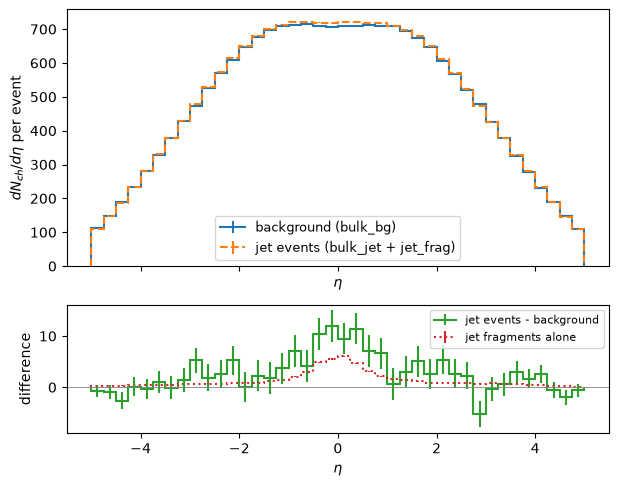

In [6]:
import hist
import mplhep as mh
import matplotlib.pyplot as plt

def to_hist(values, errors, edges, name, label):
    h = hist.Hist(hist.axis.Variable(edges, name=name, label=label), storage=hist.storage.Weight())
    h.view().value, h.view().variance = values, np.asarray(errors) ** 2
    return h

eta_edges = np.linspace(-5, 5, 41)
deta = np.diff(eta_edges)
h_bg = to_hist(*r.hist("bulk_bg", "eta", eta_edges, mask="charged"), eta_edges, "eta", r"$\eta$")
h_bulk_jet = to_hist(*r.hist("bulk_jet", "eta", eta_edges, mask="charged"), eta_edges, "eta", r"$\eta$")
h_frag = to_hist(*r.hist("jet_frag", "eta", eta_edges, mask="charged"), eta_edges, "eta", r"$\eta$")
h_jetev = h_bulk_jet + h_frag

fig, (ax, ax2) = plt.subplots(2, 1, figsize=(7, 5.5), sharex=True, height_ratios=[2, 1])
mh.histplot(h_bg / deta, ax=ax, label="background (bulk_bg)", flow="none")
mh.histplot(h_jetev / deta, ax=ax, label="jet events (bulk_jet + jet_frag)", flow="none", ls="--")
ax.set(ylabel=r"$dN_{ch}/d\eta$ per event", ylim=(0, None))
ax.legend(fontsize=9)
mh.histplot((h_jetev + (-1) * h_bg) / deta, ax=ax2, label="jet events - background", flow="none", color="C2")
mh.histplot(h_frag / deta, ax=ax2, label="jet fragments alone", flow="none", color="C3", ls=":")
ax2.axhline(0, color="0.5", lw=0.6)
ax2.set(ylabel="difference", xlabel=r"$\eta$")
ax2.legend(fontsize=8)
mid = slice(19, 21)                                   # the two bins around eta = 0
print(f"dN_ch/deta at |eta| < 0.25: background {(h_bg.values()[mid] / deta[mid]).mean():.0f}, "
      f"jet events {(h_jetev.values()[mid] / deta[mid]).mean():.0f}")
excess, excess_err = r.jet_minus_background(None, None, mask=mid_charged, per_event=False, fragments=True)
frag_mid, _ = r.total("jet_frag", mask=mid_charged, per_event=False)
print(f"jet events - background at |eta| < 1: {excess[0]:.1f} +- {excess_err[0]:.1f} charged hadrons "
      f"({frag_mid:.1f} of them jet fragments)")

**What to notice.**

- **About 710 charged hadrons per unit of $\eta$ at midrapidity**, falling off towards
  $|\eta| \approx 5$: the plateau and the shoulders of a central Au+Au collision at 200 GeV.
- **The jet adds very little:** about 17 charged hadrons at $|\eta| < 1$, of which about 8
  are the jet's own fragments. The rest is the jet's wake in the fluid, which tutorial 07
  measures precisely with correlated sampling. Here the legs were sampled independently, so the
  difference has a large error (±2 on 1,400), and single bins scatter by several hadrons.
- **The jet's hadrons are centred at midrapidity but spread over several units of $\eta$**,
  though the leading parton was at $|y| < 0.6$: the other parton of the pair can sit at larger rapidity, and
  soft fragments spread out.

## 4. Identified spectra at midrapidity

Now the transverse-momentum spectra of pions, kaons and protons at $|y| < 0.5$, per event
and per unit of rapidity, summed over both charges. A callable mask selects species and
rapidity; it does not depend on the event, so `per_event=False` lets the reader bin each
background only once:

background, |y| < 0.5:  dN/dy pi 647, K 119, p+pbar 52  |  <pT> pi 0.47, K 0.66, p+pbar 0.97 GeV
highest pT bin with background hadrons: {'pi': 4.0, 'K': 4.0, 'p+pbar': 5.0} GeV


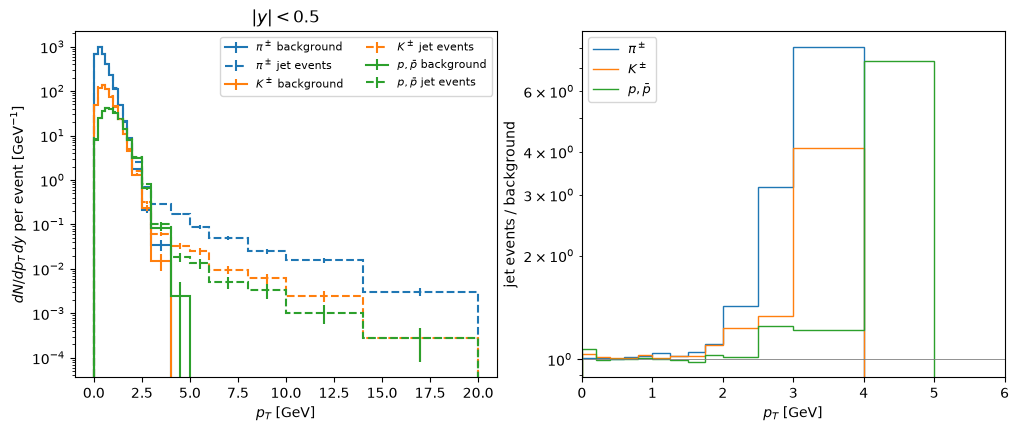

In [7]:
pt_edges = np.array([0, 0.2, 0.4, 0.6, 0.8, 1.0, 1.25, 1.5, 1.75, 2.0, 2.5, 3.0, 4.0, 5.0, 6.0, 8.0, 10.0, 14.0, 20.0])
dpt = np.diff(pt_edges)
SPECIES = {"pi": r"$\pi^\pm$", "K": r"$K^\pm$", "p+pbar": r"$p, \bar p$"}
spectra = {}
for sp in SPECIES:
    sel = lambda ev, info, sp=sp: ev.species(sp) & (np.abs(ev.y) < 0.5)
    b = to_hist(*r.hist("bulk_bg", "pt", pt_edges, mask=sel, per_event=False), pt_edges, "pt", r"$p_T$ [GeV]")
    j = to_hist(*r.hist("bulk_jet", "pt", pt_edges, mask=sel, per_event=False), pt_edges, "pt", r"$p_T$ [GeV]")
    f = to_hist(*r.hist("jet_frag", "pt", pt_edges, mask=sel, per_event=False), pt_edges, "pt", r"$p_T$ [GeV]")
    spectra[sp] = {"bg": b, "jet": j + f, "frag": f}

fig, (ax, ax2) = plt.subplots(1, 2, figsize=(12, 4.5))
for c, (sp, label) in enumerate(SPECIES.items()):
    mh.histplot(spectra[sp]["bg"] / dpt, ax=ax, label=f"{label} background", flow="none", color=f"C{c}")
    mh.histplot(spectra[sp]["jet"] / dpt, ax=ax, label=f"{label} jet events", flow="none", color=f"C{c}", ls="--")
    b = spectra[sp]["bg"].values()
    ax2.stairs(np.divide(spectra[sp]["jet"].values(), b, out=np.full(len(b), np.nan), where=b > 0),
               pt_edges, color=f"C{c}", label=label)
ax.set(yscale="log", ylabel=r"$dN/dp_T\,dy$ per event [GeV$^{-1}$]", title=r"$|y| < 0.5$")
ax.legend(fontsize=8, ncol=2)
ax2.set(yscale="log", xlabel=r"$p_T$ [GeV]", ylabel="jet events / background", xlim=(0, 6))
ax2.axhline(1, color="0.5", lw=0.6)
ax2.legend(fontsize=9)
mean_pt = {sp: (spectra[sp]["bg"].values() * spectra[sp]["bg"].axes[0].centers).sum() / spectra[sp]["bg"].values().sum()
           for sp in SPECIES}
dndy = {sp: spectra[sp]["bg"].values().sum() for sp in SPECIES}
print("background, |y| < 0.5:  dN/dy " + ", ".join(f"{sp} {dndy[sp]:.0f}" for sp in SPECIES)
      + "  |  <pT> " + ", ".join(f"{sp} {mean_pt[sp]:.2f}" for sp in SPECIES) + " GeV")
print("highest pT bin with background hadrons:",
      {sp: float(pt_edges[np.flatnonzero(spectra[sp]['bg'].values() > 0).max() + 1]) for sp in SPECIES}, "GeV")

**What to notice.**

- **Mass ordering.** The heavier the hadron, the flatter its spectrum and the larger its
  $\langle p_T \rangle$: pions about 0.5 GeV, kaons about 0.7, protons about 1.0. All three
  freeze out from the same fluid at the same temperature; the collective flow gives every
  hadron the same velocity boost, and a common velocity means more momentum for a heavier hadron.
- **The background ends at a few GeV.** A thermal source at 150 MeV, even with strong flow,
  makes very few hadrons above 3 GeV: in these 120 events the background's spectra end at
  4–5 GeV.
- **Above that, the jet events are all jet.** The ratio jet events / background is close to 1
  below 2 GeV and grows steeply above: at 3–4 GeV the jet events have several times the
  background's pions. The fragments of the jet stick out of the thermal spectrum, which is why
  high-$p_T$ hadrons are a clean probe of the jet. Protons rise last: the bulk makes many
  protons at 2–3 GeV (flow pushes them there), while the jet's fragmentation makes few.

## 5. The event record, and checks for bad runs

Each event's record (its p̂T, its background, the energy the jet gave to the fluid, ...) is
in the `units/` group of the jet files. One table for the whole campaign:

In [8]:
import pandas as pd
import h5py

cols = ["pthat_bin", "pthat", "bg_unit", "n_coll", "E_droplets", "n_droplets", "n_cells_jet", "n_cells_bg",
        "bg_hit_edge", "jet_hit_boundary", "event_weight"]
frames = []
for stem in r.stems:
    with h5py.File(stem + "_hadrons_jet_frag.h5", "r") as f:
        n = int(f.attrs["nunits_written"])
        d = pd.DataFrame({c: f["units"][c][:n] for c in cols})
    d.insert(0, "job", os.path.basename(stem).split("_seed")[1])
    frames.append(d)
events = pd.concat(frames, ignore_index=True)
events["cells_bg/jet"] = events["n_cells_bg"] / events["n_cells_jet"]
events.head(6).round(3)

,job,pthat_bin,pthat,bg_unit,n_coll,E_droplets,n_droplets,n_cells_jet,n_cells_bg,bg_hit_edge,jet_hit_boundary,event_weight,cells_bg/jet
0,0201,0,12.126,0,1072,26.066,14,1158163,1148811,0,0,1.0,0.992
1,0201,1,21.409,0,1072,32.174,20,1160147,1148811,0,0,1.0,0.990
2,0201,2,36.906,0,1072,48.576,39,1157912,1148811,0,0,1.0,0.992
3,0201,0,10.750,0,1072,57.210,27,1155209,1148811,0,0,1.0,0.994
4,0201,1,23.388,0,1072,28.206,21,1161787,1148811,0,0,1.0,0.989
5,0201,2,30.622,0,1072,74.438,28,1160091,1148811,0,0,1.0,0.990


Each row is one event; the global event number of the reader is the row number. The six events
of a background share its `n_coll` (the number of binary nucleon–nucleon collisions of that
collision) and its `n_cells_bg`. `event_weight` is 1: each p̂T window is generated without
internal weights, so its weight comes from its cross section (section 6).

**Two rare failures** show up in the data and not in the logs
([Hadrons §6](https://jhputschke.github.io/js-contrib/analysis/hadrons/#6-bad-runs)):

1. **A leg that never froze out.** Then its freeze-out surface is incomplete: the background
   would have about 3 times the cells of its jet leg (or the reverse). The ratio
   `n_cells_bg / n_cells_jet` should be within 20 % of 1.
2. **A job whose jets lost almost no energy.** Its droplets per event fall far below the
   campaign's. `utils/check_deposition.py` flags a job below half the campaign's median; the
   same test is easy here:

1. n_cells_bg / n_cells_jet: 0.977 .. 0.999; events off by more than 20 %: 0
2. droplets per event, per job: {'0201': 20.6, '0202': 24.4, '0203': 19.2, '0204': 24.7} | median 22.5
   jobs below half the median: []
   backgrounds that reached the grid edge: 0, jet legs at the boundary: 0
mean energy given to the fluid per window [GeV]: {0: 36.8, 1: 42.5, 2: 44.4} | range 3 .. 100


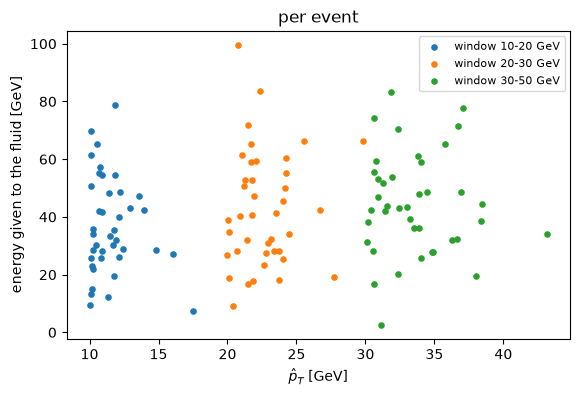

In [9]:
ratio = events["cells_bg/jet"]
print(f"1. n_cells_bg / n_cells_jet: {ratio.min():.3f} .. {ratio.max():.3f}; "
      f"events off by more than 20 %: {int(((ratio - 1).abs() > 0.2).sum())}")
per_job = events.groupby("job")["n_droplets"].mean()
median = per_job.median()
print("2. droplets per event, per job:", per_job.round(1).to_dict(), f"| median {median:.1f}")
print(f"   jobs below half the median: {list(per_job[per_job < 0.5 * median].index)}")
print(f"   backgrounds that reached the grid edge: {int(events['bg_hit_edge'].sum())}, "
      f"jet legs at the boundary: {int(events['jet_hit_boundary'].sum())}")

fig, ax = plt.subplots(figsize=(6.5, 4))
for k, (lo, hi) in enumerate(r.pthat_bins):
    s = events[events["pthat_bin"] == k]
    ax.scatter(s["pthat"], s["E_droplets"], s=14, label=f"window {lo:.0f}-{hi:.0f} GeV")
ax.set(xlabel=r"$\hat p_T$ [GeV]", ylabel="energy given to the fluid [GeV]", title="per event")
ax.legend(fontsize=8)
print("mean energy given to the fluid per window [GeV]:",
      events.groupby("pthat_bin")["E_droplets"].mean().round(1).to_dict(),
      f"| range {events['E_droplets'].min():.0f} .. {events['E_droplets'].max():.0f}")

**What to notice.**

- **No bad runs.** The cell ratios stay within a few per cent of 1, and every job's droplets per
  event are close to the median. A failed leg (ratio ≈ 3) or a job with almost no deposition
  would stand out at once.
- **The deposited energy varies far more from jet to jet than with p̂T.** At the same p̂T it
  ranges over a factor of ten; the window means grow only slowly with p̂T. How much a jet gives
  to the fluid depends on the path of its partons through the fireball and on how long they stay
  in it. It can even exceed $2\hat p_T$: p̂T is the *transverse* momentum, while the partons'
  energy also counts their longitudinal momentum, and the event's other partons from PYTHIA
  (initial-state radiation, multiple parton interactions) lose energy too.

## 6. p̂T windows and their cross sections

PYTHIA generates hard scatterings with a steeply falling p̂T distribution. To get events at large
p̂T without generating millions at low p̂T, the production splits p̂T into **windows** and
generates the same number of events in each. Each window $k$ then stands for a different
probability: its **cross section** $\sigma_k$, which PYTHIA estimates while it generates the window.
The production records it per job:

In [10]:
rows = []
for k, (lo, hi) in enumerate(r.pthat_bins):
    sig, sig_err = r.pthat_bin_sigma(k)
    acc, acc_err = r.pthat_bin_acceptance(k)
    rows.append({"window [GeV]": f"{lo:.0f}-{hi:.0f}", "events": len(r.pthat_bin_events(k)),
                 "sigma [mb]": sig, "error [mb]": sig_err, "rel. error": sig_err / sig,
                 "parton-y acceptance": acc})
windows = pd.DataFrame(rows).set_index("window [GeV]")
sigma = windows["sigma [mb]"].to_numpy()
print("sigma_k / sigma_0:", (sigma / sigma[0]).round(5))
windows.style.format({"sigma [mb]": "{:.3e}", "error [mb]": "{:.2e}", "rel. error": "{:.1%}",
                      "parton-y acceptance": "{:.2f}"})

sigma_k / sigma_0: [1.000e+00 1.308e-02 9.000e-04]


,events,sigma [mb],error [mb],rel. error,parton-y acceptance
window [GeV],,,,,
10-20,40,2.853e-03,3.56e-04,12.5%,0.51
20-30,40,3.731e-05,4.67e-06,12.5%,0.49
30-50,40,2.570e-06,2.95e-07,11.5%,0.75


The cross section includes the cut on the partons' rapidity: PYTHIA's estimate times the fraction
of generated scatterings that passed it (the acceptance). The three windows have the same number
of events, but the second is about 75 times, and the third about 1,100 times, less likely than
the first.

**Combining windows.** For each window, the reader gives the per-event average $\langle h\rangle_k$
of a histogram. A p̂T-inclusive result is the cross-section-weighted sum

$$\frac{d\sigma}{dp_T} = \sum_k \sigma_k\,\langle h \rangle_k ,$$

in mb/GeV, or divided by $\sum_k \sigma_k$, the per-event average of a sample with the natural p̂T
distribution (above 10 GeV). Each window's per-event mean already removes its own number of events,
so the windows can have different event counts.

Here is the charged-hadron spectrum of the jet fragments at $|\eta| < 1$, window by window, their
sum, and what you get by simply pooling all 120 events:

pT 2-3 GeV: windows' shares [0.955 0.04  0.005], pooled / weighted = 3.2
pT 10-12 GeV: windows' shares [0.    0.758 0.242], pooled / weighted = 110.4
pT 20-25 GeV: windows' shares [0. 0. 1.], pooled / weighted = 375.2
window 10-20 GeV, hadrons counted above 6 GeV: {'6-8': 3, '8-10': 0, '10-12': 0, '12-15': 1, '15-20': 0, '20-25': 0, '25-30': 0, '30-40': 0}


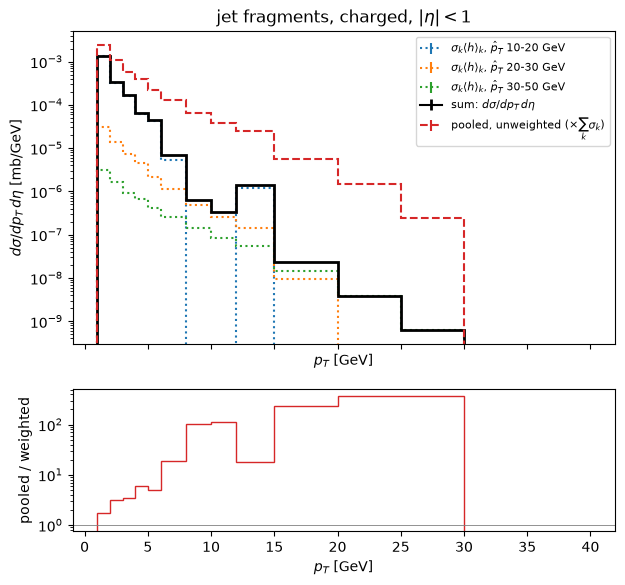

In [11]:
frag_edges = np.array([1, 2, 3, 4, 5, 6, 8, 10, 12, 15, 20, 25, 30, 40])
width = np.diff(frag_edges) * 2.0            # per GeV and per unit of eta (|eta| < 1)
per_window = []
for k in range(len(r.pthat_bins)):
    h, e = r.hist("jet_frag", "pt", frag_edges, mask=mid_charged, events=r.pthat_bin_events(k))
    per_window.append(to_hist(h, e, frag_edges, "pt", r"$p_T$ [GeV]"))
combined = sum((per_window[k] * sigma[k] for k in range(3)), start=per_window[0] * 0)
pooled = to_hist(*r.hist("jet_frag", "pt", frag_edges, mask=mid_charged), frag_edges, "pt", r"$p_T$ [GeV]")
pooled_sigma = pooled * sigma.sum()          # pooled per-event spectrum, scaled to the same total cross section

fig, (ax, ax2) = plt.subplots(2, 1, figsize=(7, 6.5), sharex=True, height_ratios=[2.2, 1])
for k, (lo, hi) in enumerate(r.pthat_bins):
    mh.histplot(per_window[k] * sigma[k] / width, ax=ax, flow="none", ls=":", color=f"C{k}",
                label=rf"$\sigma_k \langle h\rangle_k$, $\hat p_T$ {lo:.0f}-{hi:.0f} GeV")
mh.histplot(combined / width, ax=ax, flow="none", color="k", lw=2, label=r"sum: $d\sigma/dp_T\,d\eta$")
mh.histplot(pooled_sigma / width, ax=ax, flow="none", color="C3", ls="--",
            label=r"pooled, unweighted ($\times \sum_k \sigma_k$)")
ax.set(yscale="log", ylabel=r"$d\sigma/dp_T\,d\eta$ [mb/GeV]", title=r"jet fragments, charged, $|\eta|<1$")
ax.legend(fontsize=8)
with np.errstate(invalid="ignore"):                 # 0/0 in the empty last bin
    r_pool = pooled_sigma.values() / combined.values()
    share = np.array([sigma[k] * per_window[k].values() / combined.values() for k in range(3)])
ax2.stairs(r_pool, frag_edges, color="C3")
ax2.axhline(1, color="0.5", lw=0.6)
ax2.set(yscale="log", ylabel="pooled / weighted", xlabel=r"$p_T$ [GeV]")
c = combined.values()
for lo_pt in (2, 10, 20):
    b = np.searchsorted(frag_edges, lo_pt)
    print(f"pT {frag_edges[b]:.0f}-{frag_edges[b + 1]:.0f} GeV: windows' shares {share[:, b].round(3)}, "
          f"pooled / weighted = {r_pool[b]:.1f}")
n0_hadrons = per_window[0].values() * len(r.pthat_bin_events(0)) * r.n_frag(0)   # counts: 40 events x 10 fragmentations
print("window 10-20 GeV, hadrons counted above 6 GeV:",
      {f"{lo:.0f}-{hi:.0f}": int(round(n)) for lo, hi, n in zip(frag_edges[5:-1], frag_edges[6:], n0_hadrons[5:])})

**What to notice.**

- **Each window covers its own range of hadron $p_T$**, and the windows overlap. The lowest window
  dominates the sum up to 6–8 GeV, the middle one around 10 GeV, and the highest one above 15 GeV.
- **A single hadron can make a spike.** In the lowest window one hadron of 40 events × 10
  fragmentations weighs $\sigma_0/400$, more than the whole of the upper windows in that bin.
  The 12–15 GeV bin holds exactly one such hadron (printed above), and the sum jumps there. Where
  a window runs out of statistics, its last few hadrons give spikes like this. The cure is more
  events in that window, or windows whose ranges match the $p_T$ you study.
- **Pooling is wrong by large factors.** Pooling the 120 events gives each window the weight 1/3.
  The true weights are $\sigma_k / \sum\sigma$: about 0.99, 0.013 and 0.001. Pooling therefore
  overweights the upper windows by factors of about 25 and 400. The pooled spectrum is too high
  everywhere: by a factor of 2–3 at a few GeV, and by a factor of 100 or more above 8 GeV (less
  only in the bin of the spike). Its shape says more about our choice of windows than about physics.
- **The sum is the spectrum of hard scatterings with p̂T > 10 GeV.** Scatterings below 10 GeV
  were not generated. They would add to the hadron spectrum at low $p_T$, so below several GeV
  the sum is incomplete. Choose the lowest window's edge low enough for the $p_T$ range you study.

**And the bulk?** For bulk observables, each window is the same backgrounds with a different jet
on top. The jet's own share is small, so the windows differ little, and the weighted sum is
practically the lowest window. Per window, at $|\eta| < 1$:

In [12]:
rows = []
for k, (lo, hi) in enumerate(r.pthat_bins):
    g = r.pthat_bin_events(k)
    wake, wake_err = r.jet_minus_background(None, None, mask=mid_charged, events=g, per_event=False)
    frag, frag_err = r.total("jet_frag", mask=mid_charged, events=g, per_event=False)
    rows.append({"window [GeV]": f"{lo:.0f}-{hi:.0f}", "fragments": frag, "+-": frag_err,
                 "bulk_jet - bulk_bg": wake[0], "+- ": wake_err[0]})
by_window = pd.DataFrame(rows).set_index("window [GeV]")
w = sigma / sigma.sum()
print("sigma-weighted: fragments", round(float(w @ by_window["fragments"]), 2),
      "| bulk_jet - bulk_bg", round(float(w @ by_window["bulk_jet - bulk_bg"]), 2))
by_window.round(2)

sigma-weighted: fragments 4.34 | bulk_jet - bulk_bg 7.3


,fragments,+-,bulk_jet - bulk_bg,+-
window [GeV],,,,
10-20,4.29,0.10,7.23,2.67
20-30,7.59,0.14,13.16,2.67
30-50,11.57,0.17,7.24,2.67


**What to notice.** The jet's fragments at midrapidity grow with p̂T, from about 4 to about 12
charged hadrons. The wake (`bulk_jet - bulk_bg`) is too noisy here to see a trend: with
independent sampling its error is about ±2.7 per window. The errors of the bulk terms in different
windows are correlated, since all three windows use the same 20 backgrounds; for `jet_frag` the
windows are independent.

## 7. How well is a window's cross section known?

PYTHIA estimates $\sigma_k$ by Monte Carlo integration, from the events it generated in that window.
These jobs generated very few: 10 accepted events per window and job, after the rapidity cut threw
away about half of the 14–24 tried. Two things limit the estimate:
- PYTHIA's own integration error, which falls like $1/\sqrt{N_\text{tried}}$;
- the acceptance of the parton cut, a binomial fraction: 10 kept of 19 tried is 0.53 ± 0.11, a
  22 % error. This is most of each job's error.

Each job made its own estimate. Compare the four:

tried events per job and window:
 [[19 16 15]
 [24 20 12]
 [14 21 12]
 [21 24 14]]
per-job relative errors: [0.24 0.25 0.22] | combined: [0.125 0.125 0.115]
chi2 of the four estimates around the combined value (3 degrees of freedom): [1.3 2.5 2.3]


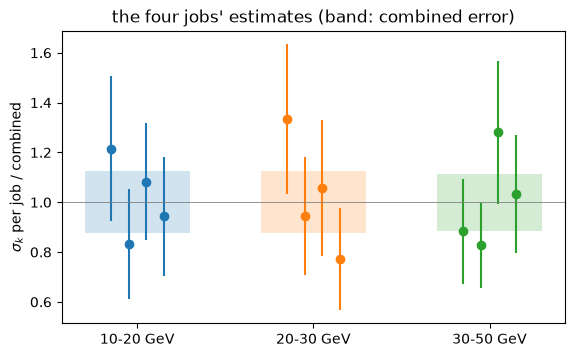

In [13]:
attrs = ["pthat_bin_sigma_gen", "pthat_bin_sigma_err", "pthat_bin_n_tried", "pthat_bin_n_kept"]
job_attrs = []
for stem in r.stems:
    with h5py.File(stem + "_hadrons_jet_frag.h5", "r") as f:
        job_attrs.append({a: f.attrs[a] for a in attrs})
sig_job = np.array([j["pthat_bin_sigma_gen"] for j in job_attrs])          # (jobs, windows)
err_job = np.array([j["pthat_bin_sigma_err"] for j in job_attrs])
tried = np.array([j["pthat_bin_n_tried"] for j in job_attrs])
sig_err = windows["error [mb]"].to_numpy()

fig, ax = plt.subplots(figsize=(6.5, 3.8))
for k, (lo, hi) in enumerate(r.pthat_bins):
    x = k + np.linspace(-0.15, 0.15, len(r.stems))
    ax.errorbar(x, sig_job[:, k] / sigma[k], err_job[:, k] / sigma[k], fmt="o", color=f"C{k}")
    ax.fill_between([k - 0.3, k + 0.3], 1 - sig_err[k] / sigma[k], 1 + sig_err[k] / sigma[k],
                    color=f"C{k}", alpha=0.2, lw=0)
ax.axhline(1, color="0.5", lw=0.6)
ax.set(xticks=range(3), xticklabels=[f"{lo:.0f}-{hi:.0f} GeV" for lo, hi in r.pthat_bins],
       ylabel=r"$\sigma_k$ per job / combined", title="the four jobs' estimates (band: combined error)")
chi2 = (((sig_job - sigma) / err_job) ** 2).sum(axis=0)
print("tried events per job and window:\n", tried)
print("per-job relative errors:", (err_job / sig_job).mean(axis=0).round(2),
      "| combined:", (sig_err / sigma).round(3))
print("chi2 of the four estimates around the combined value (3 degrees of freedom):", chi2.round(1))

**What to notice.**

- **Each job's estimate is uncertain by about 20–25 %**, and the four scatter by about that much.
  Combined, the error is about 12 % per window. The jobs agree with each other within their
  errors (a $\chi^2$ between 1 and 3 for 3 degrees of freedom), so the quoted errors are realistic.
- **This error is a normalisation.** It moves a whole window up or down, the same for every $p_T$
  bin. It does not shrink with more oversamples, only with more tried events.
- **It does not depend on the medium.** The hard scattering is the same PYTHIA process in Au+Au as
  in p+p. So the cross sections can come from a separate, cheap PYTHIA run with many events per
  window. The p+p reference `pp_ref` has 1,500 events per window (500 per job); tutorial 08 uses
  its cross sections, which are known to about 2 %.

How much does the 12 % matter for the combined spectrum? Compare it with the statistical errors,
window by window. Two statistical errors, as in section 2: the reader's sampling error, and the
spread of the 40 events of each window (different jets have very different fragments):

In [14]:
sampling_err = np.sqrt(combined.variances())
per_event = np.array([r.hist("jet_frag", "pt", frag_edges, mask=mid_charged, events=[g])[0]
                      for g in r.events()])                    # (events, bins): each event's mean
event_err = np.sqrt(sum((sigma[k] * per_event[r.pthat_bin_events(k)].std(axis=0, ddof=1)
                         / np.sqrt(len(r.pthat_bin_events(k)))) ** 2 for k in range(3)))
norm_err = np.sqrt(sum((sig_err[k] * per_window[k].values()) ** 2 for k in range(3)))
print("relative errors of the weighted spectrum:")
for lo_pt in (2, 5, 10, 20):
    b = np.searchsorted(frag_edges, lo_pt)
    print(f"  pT {frag_edges[b]:.0f}-{frag_edges[b + 1]:.0f} GeV: sampling {sampling_err[b] / c[b]:5.1%}, "
          f"event to event {event_err[b] / c[b]:5.1%}, cross sections {norm_err[b] / c[b]:5.1%}")

relative errors of the weighted spectrum:
  pT 2-3 GeV: sampling 10.0%, event to event 18.6%, cross sections 11.9%
  pT 5-6 GeV: sampling 27.2%, event to event 42.4%, cross sections 11.8%
  pT 10-12 GeV: sampling 23.1%, event to event 28.1%, cross sections  9.9%
  pT 20-25 GeV: sampling 40.8%, event to event 45.0%, cross sections 11.5%


**What to notice.**

- **The event-to-event spread is the larger statistical error**, almost twice the sampling error at
  a few GeV. The 40 jets of a window differ much more from each other than ten fragmentations of the
  same jet do. As in section 2: more fragmentations do not replace more events.
- **The cross sections' 12 % is about as large as the statistical error at a few GeV, and smaller
  at high $p_T$.** With 40 events per window, statistics dominate. Once each window has a few
  hundred events, the cross sections' error takes over, unless they come from a high-statistics
  PYTHIA run. Quote both.

### Check your result

In [15]:
import json
exp = json.load(open("expected/05_hadrons.json"))
np.testing.assert_allclose(n_bg, exp["n_mid_charged_bg"], rtol=1e-6)
np.testing.assert_allclose(n_jet, exp["n_mid_charged_jet_leg"], rtol=1e-6)
np.testing.assert_allclose(excess[0], exp["excess_mid_charged"], rtol=1e-6)
np.testing.assert_allclose([dndy[s] for s in SPECIES], exp["dndy_pi_K_p"], rtol=1e-6)
np.testing.assert_allclose(sigma, exp["sigma_mb"], rtol=1e-6)
np.testing.assert_allclose(c, exp["frag_spectrum_weighted"], rtol=1e-6)
assert ((ratio - 1).abs() < 0.2).all() and (per_job >= 0.5 * median).all()
assert np.all(event_err[:5] >= sampling_err[:5])
print("All checks pass.")

All checks pass.


## Exercises

1. **Pooling with weights.** Fill one histogram from all 120 events, but give each event the weight
   $\sigma_k / N_k$ of its window ($N_k$ = 40). Check that this reproduces `combined`. Why is it the
   same thing?
2. **The wake per window.** In section 6 the wake per window had errors of ±2.7. How many events per
   window would you need to see a difference of 3 hadrons between the windows at 3 standard
   deviations? Compare with the correlated sampling of tutorial 07.
3. **Strange baryons.** Repeat section 4 for Λ (pid 3122) and Ω (pid 3334) with a mask
   `np.isin(np.abs(ev.pid), [3122])`. How do their $\langle p_T \rangle$ fit in the mass ordering?
4. **One background, six jets.** Take the six events of background 0 (`events` rows 0–5). Plot
   their `jet_frag` charged-hadron $p_T$ spectra separately. Which differ most, and why?

## Next steps

- Jets from these hadrons, and the jet suppression against the p+p reference: tutorial 08 and [Jets with FastJet](https://jhputschke.github.io/js-contrib/analysis/jets/).
- The same hadrons in ROOT: tutorials 09 and 10, and [ROOT and C++](https://jhputschke.github.io/js-contrib/analysis/root/).
- The wake in hadrons with correlated sampling: tutorial 07 and [Hydro and hadrons together](https://jhputschke.github.io/js-contrib/analysis/hydro-hadrons/#4-the-wake-at-hadron-level).
- Everything the reader does: [Hadrons](https://jhputschke.github.io/js-contrib/analysis/hadrons/).